In [ ]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from jaxopt import AndersonAcceleration
import pickle
import os
import optax
from scipy import stats
import pandas as pd
import seaborn as sns

# Model parameters
m = 2  # Number of mitral neurons (glomeruli)
x = jnp.ones(m)  # Input odour signal

In [2]:
# Naka-Rushton function

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

Note above for Naka-Rushton, floating point exponent is not defined for negative numbers (gives nan)

In [3]:
def unpack_theta(theta, m):
    w_osn_r = jnp.array([theta[0], theta[0]])
    w_osn_b = jnp.array([theta[1], theta[1]])
    w_osn_g = jnp.array([theta[2], theta[2]])
    w_osn_y = jnp.array([theta[3], theta[3]])
    w_b_r = jnp.array([theta[4], theta[4]])
    w_b_g = jnp.array([theta[5], theta[5]])
    w_b_y = jnp.array([theta[6], theta[6]])
    w_r_y = jnp.array([theta[7], theta[7]])
    w_r_g = jnp.array([theta[8], theta[8]])
    alpha = jnp.array([theta[9], theta[9]])
    W_g_r = jnp.array([[0.0, theta[10]], [theta[10], 0.0]])
    W_g_y = jnp.array([[0.0, theta[11]], [theta[11], 0.0]])
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y


In [4]:

'''
# Unpack parameters
def unpack_theta(theta, m):
    idx = 0
    w_osn_r = theta[idx:idx+m]; idx += m
    w_osn_b = theta[idx:idx+m]; idx += m
    w_osn_g = theta[idx:idx+m]; idx += m
    w_osn_y = theta[idx:idx+m]; idx += m
    w_b_r = theta[idx:idx+m]; idx += m
    w_b_g = theta[idx:idx+m]; idx += m
    w_b_y = theta[idx:idx+m]; idx += m
    w_r_y = theta[idx:idx+m]; idx += m
    w_r_g = theta[idx:idx+m]; idx += m
    alpha = theta[idx:idx+m]; idx += m
    W_g_r = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    W_g_y = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y
'''

# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g)

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b, n_g):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    # Create a function with the n values baked in that matches AndersonAcceleration signature
    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g)

    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-8, maxiter=100)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r, n_b, n_g, n_y):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b, n_g)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

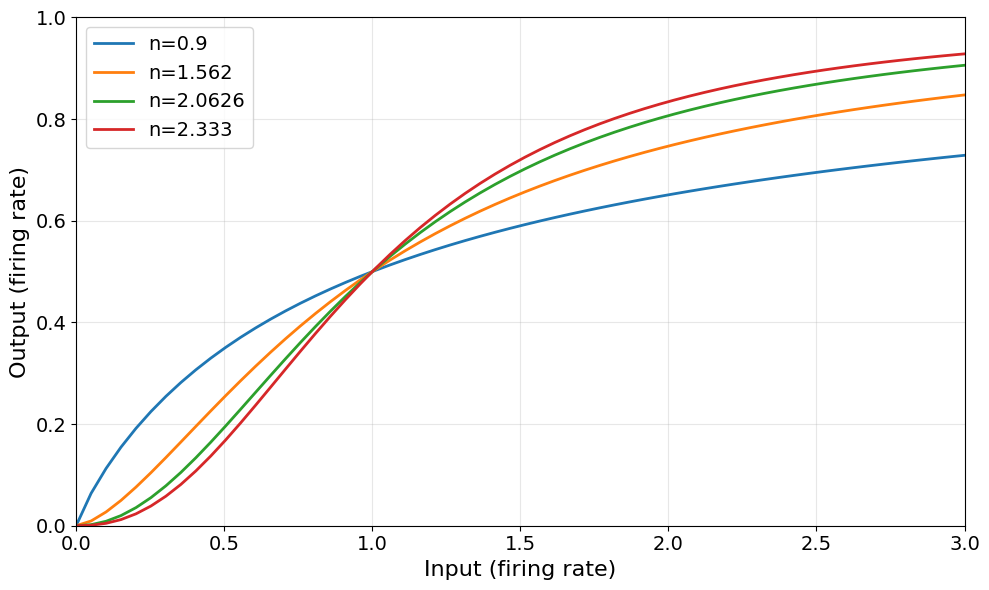

In [5]:
# Visualise the Naka-Rushton function
x_vals = jnp.linspace(0, 5, 100)
n_values = [0.9, 1.562, 2.0626, 2.333]

plt.figure(figsize=(10, 6))
for n in n_values:
    y_vals = nr(x_vals, n=n)
    plt.plot(x_vals, y_vals, label=f'n={n}', linewidth=2)

plt.xlabel('Input (firing rate)', fontsize=16)
plt.ylabel('Output (firing rate)', fontsize=16)
plt.grid(True, alpha=0.3)
plt.xlim(0, 3)
plt.ylim(0, 1)
#plt.axhline(y=0.5, color='r', linestyle='--', alpha=0.5, label='Target firing rate (0.5)')
plt.tick_params(axis='both', direction='out', labelsize=14)
plt.legend(fontsize=14)
plt.tight_layout()
plt.show()

# Parameter Initialisation

In [6]:
# set up optimisation problem
m = 2  # number of mitral neurons
n_var = 4  # r, g, b, y
n = n_var * m  # total state length
x = jnp.ones(m)  # input odour signal

# Naka-Rushton n values for each neuron type
n_r = 2.333   # red neurons (ETCs)
n_b = 0.9    # blue neurons
n_g = 2.0626  # green neurons
n_y = 1.562   # yellow/mitral neurons

# target firing rates (all neurons should fire around 0.5)
y_target = jnp.array([0.5, 0.5])  # mitral cell output
g_target = jnp.array([0.5, 0.5])  # green neurons
b_target = jnp.array([0.5, 0.5])  # blue neurons
r_target = jnp.array([0.5, 0.5])  # red neurons

# number of parameters in the model
# parameters: w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g,
#            alpha, W_g_r, W_g_y
no_params = 12  # total number of parameters

print(f"Setup:")
print(f"  - Number of mitral neurons (channels): {m}")
print(f"  - Number of parameters: {no_params}")
print(f"  - Target firing rates: {np.array(y_target)}")
print(f"  - Input signal: {np.array(x)}")
print(f"  - N values: n_r={n_r}, n_b={n_b}, n_g={n_g}, n_y={n_y}")

Setup:
  - Number of mitral neurons (channels): 2
  - Number of parameters: 12
  - Target firing rates: [0.5 0.5]
  - Input signal: [1. 1.]
  - N values: n_r=2.333, n_b=0.9, n_g=2.0626, n_y=1.562


In [7]:
# define loss function
def loss_fn(theta):
    """Loss function: sum of squared differences from target firing rates"""
    r, g, b, y = mitral_output(theta, x, m, n_r=n_r, n_b=n_b, n_g=n_g, n_y=n_y)
    loss = (jnp.sum((r - r_target) ** 2) +
            jnp.sum((g - g_target) ** 2) +
            jnp.sum((b - b_target) ** 2) +
            jnp.sum((y - y_target) ** 2))
    return loss

In [8]:
def adam_optimiser(loss_fn, theta_init, lr=0.02, steps=1500, beta1=0.9, beta2=0.999, eps=1e-8, max_grad_norm=3.0):
    """
    Adam optimiser using optax (JAX-native optimization library)
    """

    grad_fn = jax.jit(jax.grad(loss_fn))
    loss_fn_jit = jax.jit(loss_fn)

    # pre-compile functions
    _ = grad_fn(theta_init)
    _ = loss_fn_jit(theta_init)

    optimizer = optax.adam(learning_rate=lr, b1=beta1, b2=beta2, eps=eps)
    opt_state = optimizer.init(theta_init)

    loss_history = []
    theta = theta_init

    for step in range(steps):
        grad = grad_fn(theta)
        updates, opt_state = optimizer.update(grad, opt_state, theta)
        theta = optax.apply_updates(theta, updates)

        # keep weights non-negative
        theta = jnp.clip(theta, 0.0, None)

        # keep alpha between 0 and 1
                # keep alpha between 0 and 1
        alpha_start_idx = 9
        alpha_end_idx = 10  # alpha is now a single parameter at index 9
        theta = theta.at[alpha_start_idx:alpha_end_idx].set(
            jnp.clip(theta[alpha_start_idx:alpha_end_idx], 0.0, 1.0)
        )
        

        if step % 20 == 0 or step == steps - 1:
            loss_float = float(loss_fn_jit(theta))
            loss_history.append(loss_float)
    return theta, loss_history

In [9]:
# sample initial parameters
no_samples = 1000  # number of different starting points
key = jax.random.PRNGKey(0)
theta_matrix = jax.random.uniform(key, (no_samples, no_params), minval=0.0, maxval=1.0)

print(f"Sampled {no_samples} initial parameter sets")
print(f"Initial parameter matrix shape: {theta_matrix.shape}")

Sampled 1000 initial parameter sets
Initial parameter matrix shape: (1000, 12)


In [10]:
# run optimisation for each sample
theta_opt = jnp.zeros((no_samples, no_params))
r_opt = jnp.zeros((no_samples, m))
g_opt = jnp.zeros((no_samples, m))
b_opt = jnp.zeros((no_samples, m))
y_opt = jnp.zeros((no_samples, m))
all_loss_histories = []

print("Running Adam optimizer...\n")

for i in range(no_samples):
    print(f"Sample {i+1}/{no_samples}:")
    theta_unpacked = unpack_theta(theta_matrix[i, :], m)
    theta_init = theta_matrix[i, :]
    initial_loss = loss_fn(theta_init)
    print(f"  Initial loss: {initial_loss:.6f}")

    theta_optimised, loss_history = adam_optimiser(
        loss_fn, theta_init  
    )
    all_loss_histories.append(loss_history)

    theta_opt = theta_opt.at[i, :].set(theta_optimised)
    r, g, b, y = mitral_output(theta_optimised, x, m, n_r=n_r, n_b=n_b, n_g=n_g, n_y=n_y)

    r_opt = r_opt.at[i, :].set(r)
    g_opt = g_opt.at[i, :].set(g)
    b_opt = b_opt.at[i, :].set(b)
    y_opt = y_opt.at[i, :].set(y)

    final_loss = loss_fn(theta_optimised)
    print(f"  Final loss: {final_loss:.6f}")
    print(f"  Output y: {np.array(y)}")
    print()



Running Adam optimizer...

Sample 1/1000:
  Initial loss: 1.774986
  Final loss: 0.500000
  Output y: [0. 0.]

Sample 2/1000:
  Initial loss: 1.908634
  Final loss: 0.000000
  Output y: [0.5 0.5]

Sample 3/1000:
  Initial loss: 1.809353
  Final loss: 0.500000
  Output y: [0. 0.]

Sample 4/1000:
  Initial loss: 1.528760
  Final loss: 0.500000
  Output y: [0. 0.]

Sample 5/1000:
  Initial loss: 1.285224
  Final loss: 0.000000
  Output y: [0.50000006 0.50000006]

Sample 6/1000:
  Initial loss: 1.793040
  Final loss: 0.500000
  Output y: [0.5 0.5]

Sample 7/1000:
  Initial loss: 1.258128
  Final loss: 0.000000
  Output y: [0.5 0.5]

Sample 8/1000:
  Initial loss: 1.200391
  Final loss: 0.000000
  Output y: [0.49999997 0.49999997]

Sample 9/1000:
  Initial loss: 1.360277
  Final loss: 0.000000
  Output y: [0.5 0.5]

Sample 10/1000:
  Initial loss: 0.761727
  Final loss: 0.500000
  Output y: [0.5 0.5]

Sample 11/1000:
  Initial loss: 1.343166
  Final loss: 0.000000
  Output y: [0.5 0.5]

Sam

2026-02-23 20:15:46.711381: E external/xla/xla/service/slow_operation_alarm.cc:133] The operation took 16m9.092424s

********************************
[Compiling module jit_update] Very slow compile? If you want to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
********************************


  Final loss: 0.000000
  Output y: [0.49999997 0.49999997]

Sample 440/1000:
  Initial loss: 1.834102
  Final loss: 0.500000
  Output y: [0. 0.]

Sample 441/1000:
  Initial loss: 1.762987
  Final loss: 0.500000
  Output y: [0. 0.]

Sample 442/1000:
  Initial loss: 1.713668
  Final loss: 0.000000
  Output y: [0.5 0.5]

Sample 443/1000:
  Initial loss: 1.460671
  Final loss: 0.000000
  Output y: [0.5 0.5]

Sample 444/1000:
  Initial loss: 1.431516
  Final loss: 0.500000
  Output y: [0. 0.]

Sample 445/1000:
  Initial loss: 1.113529
  Final loss: 0.500000
  Output y: [0. 0.]

Sample 446/1000:
  Initial loss: 1.026713
  Final loss: 0.000000
  Output y: [0.50000006 0.50000006]

Sample 447/1000:
  Initial loss: 0.970715
  Final loss: 0.000000
  Output y: [0.5 0.5]

Sample 448/1000:
  Initial loss: 1.314080
  Final loss: 0.000000
  Output y: [0.5 0.5]

Sample 449/1000:
  Initial loss: 1.312930
  Final loss: 0.500000
  Output y: [0.5 0.5]

Sample 450/1000:
  Initial loss: 1.963403
  Final loss

2026-02-23 20:35:13.682560: E external/xla/xla/service/slow_operation_alarm.cc:133] The operation took 17m15.921287s

********************************
[Compiling module jit_while] Very slow compile? If you want to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
********************************


  Final loss: 0.000000
  Output y: [0.49999997 0.49999997]

Sample 500/1000:
  Initial loss: 0.918226
  Final loss: 0.000000
  Output y: [0.5 0.5]

Sample 501/1000:
  Initial loss: 1.896421
  Final loss: 0.000000
  Output y: [0.50000006 0.50000006]

Sample 502/1000:
  Initial loss: 1.581875
  Final loss: 0.500000
  Output y: [0. 0.]

Sample 503/1000:
  Initial loss: 1.474644
  Final loss: 0.500000
  Output y: [0.49999997 0.49999997]

Sample 504/1000:
  Initial loss: 1.992101
  Final loss: 0.500000
  Output y: [0. 0.]

Sample 505/1000:
  Initial loss: 1.862822
  Final loss: 0.000000
  Output y: [0.5 0.5]

Sample 506/1000:
  Initial loss: 1.711622
  Final loss: 0.500000
  Output y: [0. 0.]

Sample 507/1000:
  Initial loss: 1.998803
  Final loss: 1.500000
  Output y: [0. 0.]

Sample 508/1000:
  Initial loss: 1.634030
  Final loss: 0.500000
  Output y: [0. 0.]

Sample 509/1000:
  Initial loss: 1.614820
  Final loss: 0.000000
  Output y: [0.5 0.5]

Sample 510/1000:
  Initial loss: 1.769593


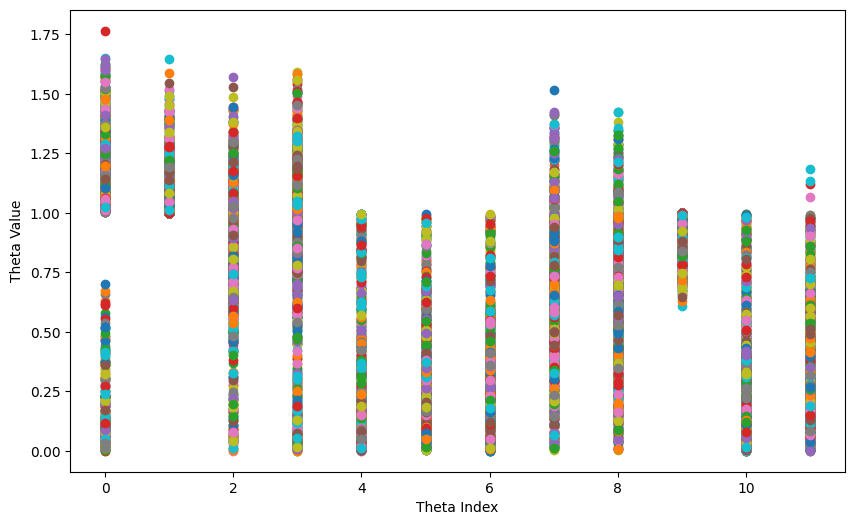

In [11]:
theta_opt.shape
plt.figure(figsize=(10, 6))
for i in range(no_samples):
    plt.plot(theta_opt[i, :], 'o', label=f'Sample {i+1}')
plt.xlabel('Theta Index')
plt.ylabel('Theta Value')
plt.show()


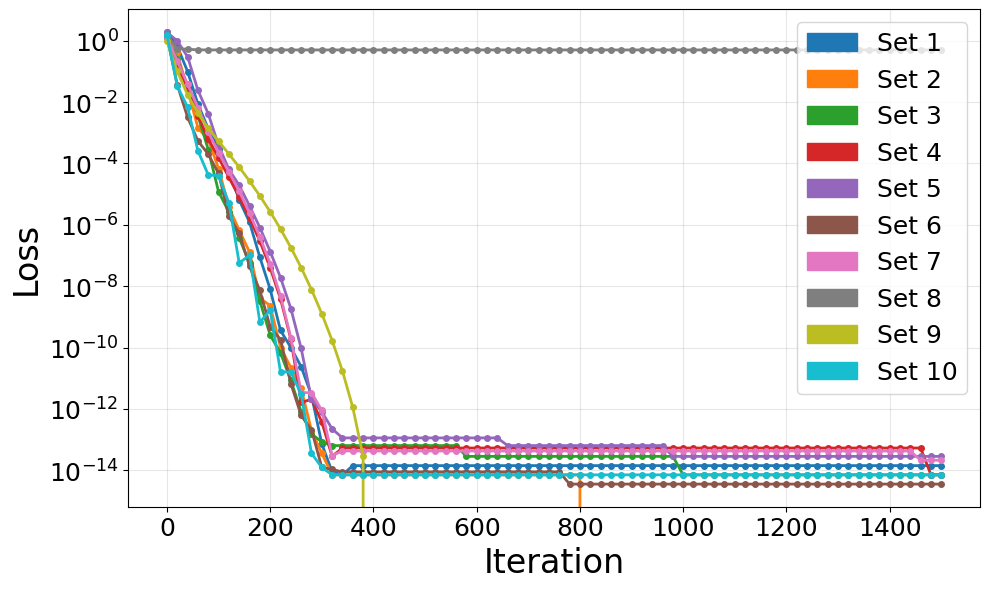

Optimization results:
Target output: [0.5 0.5]

Optimized outputs:
  Sample 1: y = [0.5 0.5]
  Sample 2: y = [0.5 0.5]
  Sample 3: y = [0.5 0.5]
  Sample 4: y = [0.5 0.5]
  Sample 5: y = [0.5 0.5]
  Sample 6: y = [0.5 0.5]
  Sample 7: y = [0.5 0.5]
  Sample 8: y = [0.5 0.5]
  Sample 9: y = [0.5 0.5]
  Sample 10: y = [0.5 0.5]


In [70]:
plt.figure(figsize=(10, 6))

# keep track of the line objects so we can get their colors
lines = []

for i, loss_hist in enumerate(all_loss_histories):
    steps = np.arange(0, len(loss_hist)) * 20
    line, = plt.plot(steps, loss_hist, 'o-', linewidth=2, markersize=4)
    lines.append(line)  # store line object

plt.xlabel('Iteration', fontsize=24)
plt.ylabel('Loss', fontsize=24)
plt.yscale('log')
#plt.xlim(0, 500)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.grid(True, alpha=0.3)

# create legend using the colors of the actual plotted lines
legend_handles = [Patch(color=line.get_color(), label=f'Set {i+1}')
                  for i, line in enumerate(lines)]
plt.legend(handles=legend_handles,loc='upper right',  fontsize=18)

plt.tight_layout()
#plt.savefig('Figures/loss_convergence.eps')
plt.show()

print("Optimization results:")
print(f"Target output: {np.array(y_target)}")
print(f"\nOptimized outputs:")
for i in range(y_opt.shape[0]):
    print(f"  Sample {i+1}: y = {np.array(y_opt[i])}")

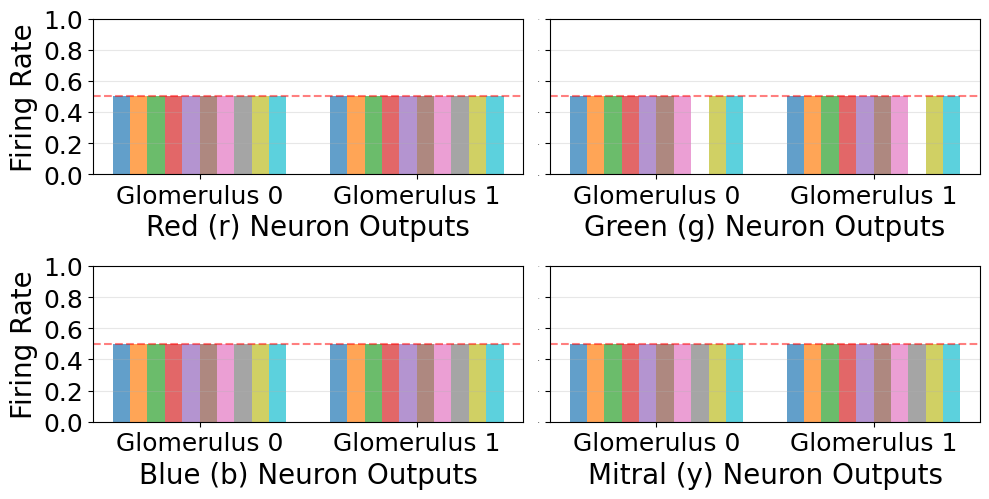

In [71]:

###############################
# plot the output values of r, g, b, y for all samples
plt.figure(figsize=(10, 6))

# create subplots for each neuron type
neuron_types = ['Red (r)', 'Green (g)', 'Blue (b)', 'Mitral (y)']
outputs = [r_opt, g_opt, b_opt, y_opt]

for idx, (neuron_type, output) in enumerate(zip(neuron_types, outputs)):
    plt.subplot(2, 2, idx + 1)

    x_pos = np.arange(m)
    width = 0.8 / y_opt.shape[0]

    # plot bars for each sample with multicolored coding
    for i in range(y_opt.shape[0]):
        plt.bar(x_pos + i*width, np.array(output[i]), width,
                label=f'Sample {i+1}' if idx == 0 else '', alpha=0.7)

    # add target line at 0.5
    plt.axhline(y=0.5, color='red', linestyle='--', linewidth=1.5,
                alpha=0.5, label='Target (0.5)')

    # Y-axis
    # only for the left plots
    if idx == 0 or idx == 2 :
        plt.ylabel('Firing Rate', fontsize=20)
        plt.yticks(fontsize=18)
    else:
        plt.yticks(fontsize=0)

    # subplot x-axis ticks
    plt.xticks(x_pos + 4.5*width, [f'Glomerulus {j}' for j in range(m)], fontsize=14)
    plt.xlabel(f'{neuron_type} Neuron Outputs', fontsize=20)
    plt.xticks(fontsize=18)
    plt.ylim([0, 1.0])
    plt.grid(True, alpha=0.3, axis='y')

# legend only once
# central x-axis label for the whole figure
plt.tight_layout(rect=[0, 0.1, 1, 0.95])
#plt.savefig('Figures/neuron_outputs_rgby.eps')
plt.show()




In [12]:
def check_single_theta_np(theta, x, m):
    """Check single theta sample - using numpy for compatibility"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_g, n_y)
    # Convert to numpy arrays
    r = np.array(r)
    g = np.array(g)
    b = np.array(b)
    y = np.array(y)

    # Check if all elements are in [0.4, 0.6]
    r_ok = (r >= 0.4).all() and (r <= 0.6).all()
    g_ok = (g >= 0.4).all() and (g <= 0.6).all()
    b_ok = (b >= 0.4).all() and (b <= 0.6).all()
    y_ok = (y >= 0.4).all() and (y <= 0.6).all()

    return r_ok and g_ok and b_ok and y_ok

# Process samples
n_samples = theta_opt.shape[0]
valid_mask = np.zeros(n_samples, dtype=bool)

for i in range(n_samples):
    theta_star = jnp.array(theta_opt[i, :])
    valid_mask[i] = check_single_theta_np(theta_star, x, m)

    if (i + 1) % 100 == 0:
        print(f"Processed {i+1}/{n_samples} samples...")

theta_opt = theta_opt[valid_mask]

print(f"Number of valid theta_opt: {theta_opt.shape[0]} out of {n_samples}")

# save theta_opt as pickle file
# create Theta_opt directory if it doesn't exist
os.makedirs('Theta_opt', exist_ok=True)

with open(f'Theta_opt/theta_opt_{theta_opt.shape[0]}_samples_n_different.pkl', 'wb') as f:
    pickle.dump(theta_opt, f)

Processed 100/1000 samples...
Processed 200/1000 samples...
Processed 300/1000 samples...
Processed 400/1000 samples...
Processed 500/1000 samples...
Processed 600/1000 samples...
Processed 700/1000 samples...
Processed 800/1000 samples...
Processed 900/1000 samples...
Processed 1000/1000 samples...
Number of valid theta_opt: 626 out of 1000
